# Ny notatbok

Skriv kode i cellene under, og kjør dem med **Shift+Enter**.

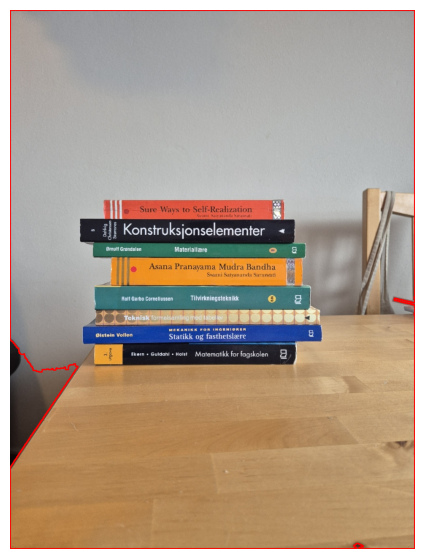

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Les inn bilde
img = cv2.imread('stack_2.png')

# 2. Gråtone og terskling
img_gray    = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, binary   = cv2.threshold(img_gray, 127, 255, cv2.THRESH_OTSU)

# 3. Morfologisk operasjon (bruk 'binary' som input)
kernel      = np.ones((7, 7), np.uint8)
thresh      = cv2.dilate(binary, kernel)

# Sikre at bildet er uint8 i tilfelle det har blitt endret tidligere
# thresh      = thresh.astype(np.uint8)

# 4. Finn konturer
contours, _ = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

# 5. Tegn kontur på fargebildet for å se den røde fargen
img_result  = img.copy()
if contours:
    # Tegner den første konturen med rød farge (BGR: (0, 0, 255))
    cv2.drawContours(img_result, [contours[0]], -1, (0, 0, 255), 2)

# 6. Visning (Matplotlib forventer RGB)
img_rgb     = cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 7))
plt.imshow(img_rgb)
plt.axis('off')
plt.show()


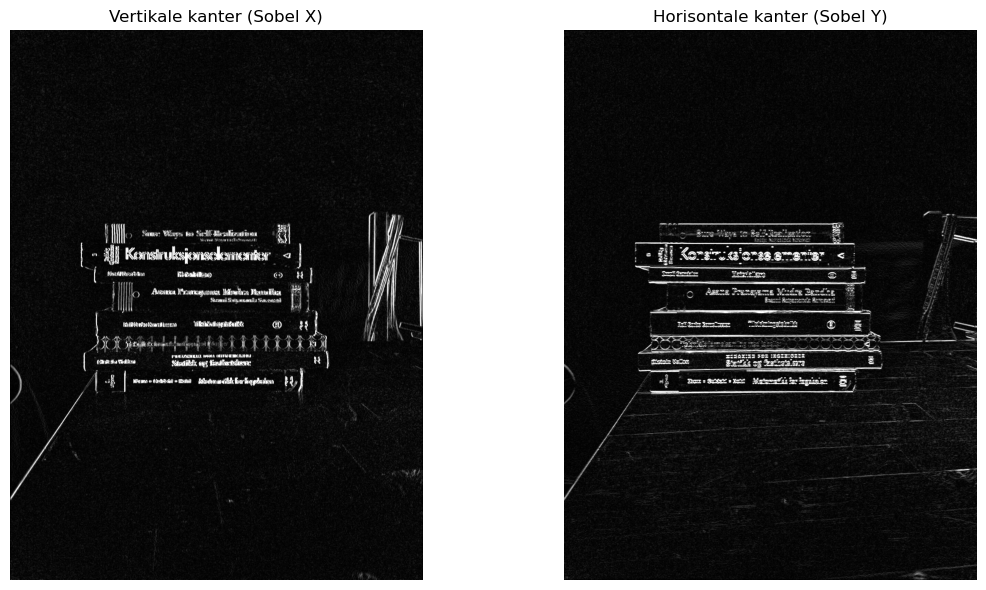

In [13]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Les inn bilde
img = cv2.imread('stack_2.png')

# 2. Gråtone og terskling
img_gray    = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_y = cv2.Sobel(img_gray, cv2.CV_64F,dx=0, dy=1, ksize=3)
sobel_x = cv2.Sobel(img_gray, cv2.CV_64F,dx=1, dy=0, ksize=3)

sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

# plt.figure(figsize=(7, 7))
# plt.subplot()
# plt.imshow(sobel_y_abs, cmap='gray')
# plt.imshow(sobel_x_abs, cmap='gray')
# plt.axis('off')
# plt.show()

# 1. Sett opp et lerret med to delplott (1 rad, 2 kolonner)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# 2. Vertikale kanter (Sobel X)
axes[0].imshow(sobel_x_abs, cmap='gray')
axes[0].set_title('Vertikale kanter (Sobel X)')
axes[0].axis('off')

# 3. Horisontale kanter (Sobel Y)
axes[1].imshow(sobel_y_abs, cmap='gray')
axes[1].set_title('Horisontale kanter (Sobel Y)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [14]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Indlæs billedet
img = cv2.imread('23_Pro.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Definer et interesseområde (ROI) omkring stakken for at fjerne baggrunden
# (Alternativt kan man bruge cv2.inRange på gul farve for automatisk maskering)
h, w = gray.shape
roi_gray = gray[int(h * 0.45):int(h * 0.95), int(w * 0.30):int(w * 0.70)]

# 3. Dæmp støj og tekstur
blurred = cv2.GaussianBlur(roi_gray, (5, 5), 0)

# 4. Vandret Sobel-filtrering (dy=1, dx=0)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, dx=0, dy=1, ksize=3)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

# 5. Filtrér svage gradienter fra (terskling)
_, thresh = cv2.threshold(sobel_y_abs, 40, 255, cv2.THRESH_BINARY)

# 6. Morfologisk lukning med en bred, vandret kernel for at forbinde linjerne
horizontal_kernel = np.ones((1, 25), np.uint8)
clean_lines = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, horizontal_kernel)

# 7. Beregn vandret intensitetsprofil (sum pr. række)
row_sums = np.sum(clean_lines, axis=1)

# Find toppe (peaks) med en minimumsafstand svarende til en bogs tykkelse
from scipy.signal import find_peaks
peaks, _ = find_peaks(row_sums, height=np.max(row_sums) * 0.3, distance=30)

antal_kanter = len(peaks)
antal_boeger = max(0, antal_kanter - 1)

print(f"Antal fundne vandrette kanter: {antal_kanter}")
print(f"Estimeret antal bøger i stakken: {antal_boeger}")

Antal fundne vandrette kanter: 4
Estimeret antal bøger i stakken: 3


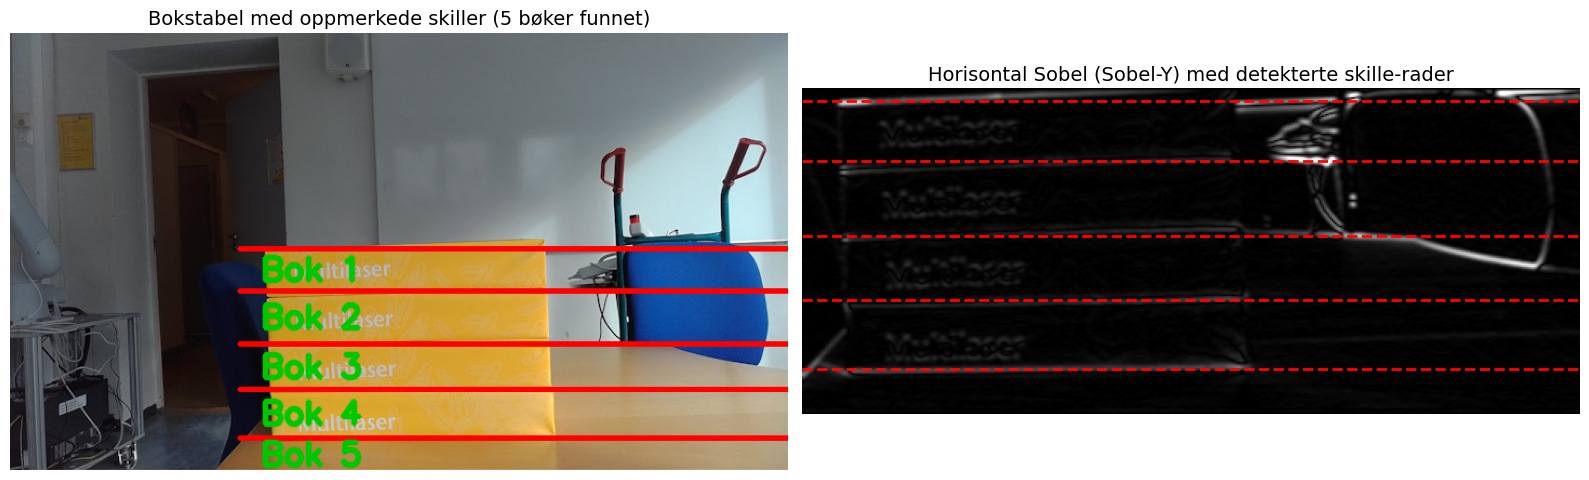

In [21]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# 1. Les inn bildet
img = cv2.imread('23_Pro.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Isoler den gule stabelen automatisk via fargemaske (HSV)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lower_yellow = np.array([15, 70, 70])
upper_yellow = np.array([35, 255, 255])
mask = cv2.inRange(hsv, lower_yellow, upper_yellow)

# Finn største kontur (selve bokstabelen)
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest_contour = max(contours, key=cv2.contourArea)
x, y, w, h = cv2.boundingRect(largest_contour)

# 3. Klipp ut området (ROI) for stabelen i gråtone
roi_gray = gray[y : y + h, x : x + w]

# 4. Glatt ut støy og tekst (GaussianBlur)
blurred = cv2.GaussianBlur(roi_gray, (7, 7), 0)

# 5. Kjør horisontal Sobel (dy=1, dx=0)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, dx=0, dy=1, ksize=3)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

# 6. Beregn intensitetsprofil (sum av pikselverdier langs hver rad)
# Vi kutter 5% av kantene på sidene for å unngå forstyrrelser fra ytterkanten
row_sums = np.sum(sobel_y_abs[:, int(w * 0.05) : int(w * 0.95)], axis=1)

# 7. Finn toppene (peaks) som representerer de horisontale skillelinjene
# 'distance' sikrer at det minst er en viss tykkelse mellom hver boklinje
min_book_thickness = int(h / 6)  # forventer ca. 4 bøker
peaks, _ = find_peaks(
    row_sums, height=np.max(row_sums) * 0.25, distance=min_book_thickness
)

# Sørg for at yttergrensene (toppen og bunnen av stakken) er med
all_lines_y = sorted(list(set([0] + list(peaks) + [h])))

# 8. Tegn linjer og tekst på en kopi av originalbildet
annotated_img = img_rgb.copy()

# Tegn skillelinjene
for py in peaks:
    global_y = y + py
    # Tegn en markant rød linje over hele bredden til stabelen
    cv2.line(annotated_img, (x, global_y), (x + w, global_y), (255, 0, 0), 4)

# 9. Merk og nummerer hver enkelt bok mellom linjene
book_count = 0
for i in range(len(all_lines_y) - 1):
    y_start = all_lines_y[i]
    y_end = all_lines_y[i + 1]

    # Filtrer bort eventuelle bittesmå feilsegmenter
    if (y_end - y_start) > min_book_thickness * 0.7:
        book_count += 1
        center_y = y + int((y_start + y_end) / 2)

        # Skriv boknummer med grønn tekst
        cv2.putText(
            annotated_img,
            f"Bok {book_count}",
            (x + 20, center_y + 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (0, 200, 0),
            3,
            cv2.LINE_AA,
        )

# 10. Vis resultatet side om side med kantgradienten
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(annotated_img)
axes[0].set_title(
    f"Bokstabel med oppmerkede skiller ({book_count} bøker funnet)", fontsize=14
)
axes[0].axis("off")

axes[1].imshow(sobel_y_abs, cmap="gray")
for py in peaks:
    axes[1].axhline(py, color="red", linestyle="--", linewidth=2)
axes[1].set_title(
    "Horisontal Sobel (Sobel-Y) med detekterte skille-rader", fontsize=14
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

Prøve I bildebehandling - Oppgave 1